[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/HybridQNN_MalwareAdversarial_Vyas2026.ipynb)

# Hybrid CNN + quantum layer for malware-image detection with QNI-CCP and adversarial training: Vyas et al. (2026), "QSLP", step by step

**Paper.** Kathan P. Vyas, Dev K. Patel, Rahul Tanna and Sameer G. Kulkarni, *Adversarially Robust Quantum-Classical Neural Network for Malware Detection*, Workshop on Advances in Malware Analysis and Software Security (AMASS '26), Bangalore, 1-5 June 2026. DOI: [10.1145/3807501.3808237](https://doi.org/10.1145/3807501.3808237).

**What this notebook does.** It rebuilds the paper's pipeline for *image-based malware family classification*:

1. a malware binary is shown as a grey-scale image (the **Malimg** dataset, 25 families);
2. a small **CNN** squeezes the image into 6 numbers (one per qubit);
3. a **6-qubit variational quantum circuit** (PennyLane: RY angle encoding, 6 layers of RY + a linear CNOT chain, Pauli-Z read-out) turns them into 6 expectation values;
4. a small **MLP head** (64 -> 32 -> 16 -> 25) predicts the family.

On top of this *basic hybrid QNN* the paper adds **QNI-CCP** (Quantum Noise Injection - Class Center Perturbation, a latent-space regulariser) and **adversarial training** with FGSM and PGD, calling the full recipe **QSLP**. The notebook trains every stage, trains the same-architecture classical CNN for comparison, attacks all models with FGSM and PGD, re-draws the paper's tables and figures, and ends with a side-by-side comparison against the paper's numbers.

**How to run.** Open in Google Colab, choose a **CPU** runtime, and use *Runtime -> Run all*. With `FAST_MODE = True` (default: 750 Malimg images, 30 / 30 / 6 / 4 training epochs) the run took about 36 minutes on a shared 4-core laptop CPU (the per-stage times are printed by the training cell); with `FAST_MODE = False` the whole of Malimg (about 9.3k images) and longer training are used. The full run was **not** executed here: from the measured per-epoch times it would take many hours on a CPU (see the configuration cell and section 10).

**What you get at the end.** Accuracy / F1 tables for every stage, FGSM and PGD robustness tables, class-wise robustness heat-maps, latent-space plots, and a per-claim verdict (reproduced / not reached / cannot be checked).

> **Dataset note (important).** The paper uses two datasets, *Malimg* and *MaleVis*. Malimg is public and is used here. MaleVis is distributed by its authors (Hacettepe University) only after filling in a request form, and no verified public mirror was found (Hugging Face search and a web search came back empty), so the MaleVis half of the paper **cannot be reproduced** and every MaleVis claim is marked "cannot be checked". The bibliography index of this repository lists "Drebin; DGA" for this paper; those names appear only in the related-work section (cited papers) and are **not** used by the experiments.

## The paper in one page

**Problem.** Image-based malware classifiers (malware binary -> grey-scale image -> CNN) generalise poorly and are fragile to adversarial pixel perturbations. Quantum layers are claimed to give more structured latent spaces, but are noise-sensitive and hard to scale. Three research questions: **RQ1** do hybrid quantum-classical models beat classical ones? **RQ2** is *latent-space* robustness enough? **RQ3** how much does *adversarial training* add?

**Decision.** Multi-class malware-family classification (25 families in Malimg, 25 families + benign in MaleVis).

**Method (QSLP).**
- *Feature extractor:* 5 strided convolutions (channels 8-16-32-64-128, BatchNorm, ReLU, dropout), adaptive average pooling to 1x1, a linear layer to `n_qubits` numbers, `tanh`.
- *Quantum layer:* angle encoding with RY, `L = 6` variational layers (RY on every qubit, then a linear CNOT chain 0->1->...->5), `<Z_i>` on every qubit; `n = 6` qubits for Malimg (10 for MaleVis).
- *Head:* MLP 6 -> 64 -> 32 -> 16 -> 25 with dropout and ReLU.
- *QNI-CCP (Eqs. 1-8):* in the latent space `z`, compute the loss sensitivity `S = dL/dz`, the class centroids `mu_c`, a random wrong target class `c'`, and perturb `z' = z + eps_q * [ S (.) (mu_c' - z) ]` with `eps_q = 1 / (1 + alpha * N_CNOT + beta * D)`, `alpha = beta = 1`.
- *Adversarial training (Algorithm 1):* loss = 0.5 clean + 0.15 QNI-CCP + 0.10 FGSM + 0.15 PGD + 0.10 centroid regulariser; AdamW, lr 5e-4, weight decay 5e-3, batch 16, gradient clipping 1.0, centroids refreshed every 5 epochs.
- *Attacks (Table 3):* FGSM eps = 0.03; PGD eps = 0.1, step 0.01, 7 iterations.

**Data.** Malimg: 9,339 grey-scale images, 25 families, strongly imbalanced (80 to ~3,000 per family); stratified 70 / 15 / 15 split; images resized to 128 x 128. MaleVis: 14,226 images, 25 families + benign, 224 x 224, 10 qubits.

**Preprocessing.** Grey-scale, resize 128 x 128, normalise to [-1, 1]; training augmentation: horizontal flip and rotation +-10 degrees (visible in the authors' code).

**Claims we can test (Malimg).**
- Table 5: basic hybrid QNN accuracy 0.94 (train) / 0.94 (val); after QNI-CCP 0.97 / 0.97; after adversarial training 0.96 / 0.95.
- Table 7: clean / FGSM / PGD accuracy, QSLP (adversarial training "M1") 95.11 / 90.32 / 80 %, classical CNN 97.09 / 95.84 / 85.22 %; "M2" (train normally, then adversarially fine-tune) hybrid 97.09 / 95.11 / 92.30 %, classical 97.61 / 95.42 / 93.24 %.
- Section 4.5: undefended models almost fail against PGD (< 10 % accuracy); QNI-CCP alone does not protect against pixel attacks; adversarial training does.
- Table 6: latent-space statistics (entropy, feature variance, confidence) of CNN, QNI-CCP and basic hybrid.
- Table 2: deeper circuits help (2 layers 80 %, 6 layers 95 %), and a ring CNOT pattern hurts (81 %).
- Throughput: 54.8 images/s (hybrid) against 7,621 images/s (classical).
- Fig. 4 (t-SNE), Fig. 5 (class-wise FGSM / PGD F1 heat-maps), Table 4 (PCA variance ratios of the latent space).

### What follows the paper and what had to be chosen

The authors' code is public (GitHub `KATHAN-VYAS/Quantum_MachineLearning`, files `Basic_QML_circuit.ipynb`, `QML_QNI-CCP.ipynb`, `QML_QNI-CCP_adv.ipynb`); where the paper text is silent this notebook follows that code. Every choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | Malimg + MaleVis | **Malimg only** (HF mirror `Iss-btu-tubitak/BTU-TUBITAK-MALIMG`, 9,347 PNG files; the paper counts 9,339). MaleVis needs a request form: not reproducible |
| Split | stratified 70 / 15 / 15, fixed seed | same, seed 42, `train_test_split` twice |
| Image size / channels | 128 x 128 grey | same (PIL bilinear resize of the original-size PNG) |
| CNN | "6 layers, channels 8 to 24", stride 2, adaptive pooling, FC | authors' code: **5** strided convs, channels 8-16-32-64-128, dropout 0.4, BatchNorm, FC to 6, `tanh` |
| Quantum layer | 6 qubits, RY encoding, 6 layers RY + linear CNOT, `<Z>` | same, PennyLane `default.qubit`; weights ~ U[0, 2 pi) |
| Quantum simulation speed | PennyLane on a GPU server | PennyLane `qnode` is the reference; **training uses an exact PyTorch twin of the same gate list** (much faster on a CPU), asserted equal in value and gradient; **all reported test metrics use the PennyLane circuit** |
| Loss (basic model) | focal loss | focal loss, gamma = 1.5, alpha = 1 (authors' code); no class weights |
| Loss (QNI-CCP stage) | not given | 0.7 CE + 0.2 CE(QNI) + 0.1 centroid regulariser (authors' code) |
| Loss (QSLP) | Algorithm 1 | exactly Algorithm 1 weights (0.5 / 0.15 / 0.10 / 0.15 / 0.10) |
| Sensitivity `S` | normalised / absolute gradient (Eq. 2) | raw signed gradient of the batch-mean cross-entropy w.r.t. `z` (authors' code), no normalisation |
| `eps_q` | `1 / (1 + a N_CNOT + b D)`, `a = b = 1` | `N_CNOT = 30`, `D = 6` (as in the authors' code) -> 0.027 |
| Attack mode | - | attacks run with the model in `eval()` mode and training mode is restored afterwards (the released code leaves the model in `eval()` after the first attack) |
| Epochs | 50 (authors' code) | see the configuration cell (CPU budget) |
| Optimiser | AdamW, lr 5e-4 (1e-4 to 5e-4), wd 5e-3, batch 16 | same; `ReduceLROnPlateau(patience=5)`; best-validation checkpoint |
| Seeds | not stated | `SEED = 42`, single run per model (CPU budget); binomial standard errors are printed |
| Table 6 definitions | "entropy", "feature variance", ... not defined | entropy of the predicted-class distribution (nats); feature variance = mean per-feature variance of the representation entering the classifier head (raw CNN output for the classical model, quantum expectation values for hybrids); confidence = max softmax |
| Throughput | images/s, hardware unknown | measured here on a shared CPU, batch 16 |

In [1]:
# Pinned installs (tested locally with these versions). Colab already ships torch, numpy, pandas,
# scikit-learn and matplotlib; PennyLane is the only package that must be added.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _need_install():
    try:
        import pennylane
        return pennylane.__version__ != "0.45.1"
    except Exception:
        return True
if IN_COLAB or _need_install():
    !pip -q install "pennylane==0.45.1" "huggingface_hub>=0.24" pillow
    # NOTE: if Colab reports a binary-incompatibility error after this cell, use Runtime -> Restart session and Run all again.

In [2]:
# ===================== CONFIGURATION (every tunable constant lives here) =====================
FAST_MODE = True            # True: ~10 min class demo on a Malimg subset. False: full Malimg, longer training.
SEED = 42                   # one seed for numpy / random / torch / sklearn / DataLoader generators

# --- data -----------------------------------------------------------------------------------
DATA_SOURCE = "hf"          # "hf" = download Malimg PNGs from Hugging Face; "local" = use LOCAL_DIR (one sub-folder per family)
LOCAL_DIR = "my_malimg"     # only used when DATA_SOURCE == "local"
DATA_DIR = "data"           # cache folder (PNG files + resized .npz)
PER_CLASS_CAP = 30 if FAST_MODE else None   # CHOICE: FAST uses at most 30 images per family (750 images); full = all (~9.3k)
IMG = 128                   # image side (paper: 128 x 128 for Malimg)
TEST_FRAC, VAL_FRAC = 0.15, 0.15            # paper: 70 / 15 / 15 stratified

# --- model (paper Section 3 / Table 3) -------------------------------------------------------
N_QUBITS = 6                # Malimg: 6 qubits
Q_LAYERS = 6                # variational layers ("circuit depth = 6")
BATCH = 16
LR = 2e-3 if FAST_MODE else 5e-4   # CHOICE: the paper's 5e-4 needs many epochs; FAST mode uses a larger rate to learn something in a few
ALPHA_Q, BETA_Q = 1.0, 1.0  # eps_q = 1 / (1 + ALPHA_Q * N_CNOT + BETA_Q * D)
EPS_FGSM = 0.03             # Table 3
EPS_PGD, ALPHA_PGD, ITERS_PGD = 0.1, 0.01, 7   # Table 3 (always used for evaluation)
ITERS_PGD_TRAIN = 3 if FAST_MODE else ITERS_PGD   # CHOICE: fewer PGD steps while *training* in FAST mode (cost)
CENTROID_EVERY = 5 if not FAST_MODE else 2     # Algorithm 1 refreshes centroids every 5 epochs

# --- training budgets (epochs). The authors use 50; CPU budgets are smaller. -----------------
EPOCHS = dict(basic=30, qni=30, qslp=6, finetune=4) if FAST_MODE else dict(basic=30, qni=30, qslp=20, finetune=10)   # authors: 50; CPU budget
RUN_ABLATION = True         # Table 2 style ablation (circuit depth, ring vs linear CNOT) with short basic-model trainings
ABLATION_EPOCHS = 6 if FAST_MODE else 10
N_THREADS = 2               # torch CPU threads

IBM_TOKEN = ""              # not used: the paper only uses simulators (kept for convention)


In [3]:
import os, sys, io, math, copy, time, random, json, platform
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_everything()
torch.set_num_threads(N_THREADS)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})

# Hugging Face token: only needed if a dataset is gated. Malimg here is public, so the token is optional.
# If you use a gated mirror, add HF_TOKEN in Colab (Settings > Secrets) or as an environment variable.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", platform.python_version(), "| torch", torch.__version__, "| pennylane", qml.__version__,
      "| sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| epochs", EPOCHS)

python 3.12.10 | torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1 | numpy 2.5.4 | pandas 3.0.6
FAST_MODE = True | epochs {'basic': 30, 'qni': 30, 'qslp': 6, 'finetune': 4}


## 1. Data: the Malimg malware images

Malimg (Nataraj et al., 2011) contains 9,339 Windows malware binaries rendered as grey-scale images (each byte becomes one pixel; the image width depends on the file size) from **25 malware families**. The classes are very imbalanced: *Allaple.A* has about 3,000 images and *Skintrim.N* only 80. Each folder name is the label.

The next cell downloads the PNG files from a public Hugging Face mirror (no token needed), resizes each to 128 x 128 (the paper's input size), and caches the result as a compressed `.npz` so reruns are instant. In `FAST_MODE` only 30 randomly chosen images per family are used. The original-size images are never modified.

In [4]:
from concurrent.futures import ThreadPoolExecutor
from PIL import Image

HF_REPO = "Iss-btu-tubitak/BTU-TUBITAK-MALIMG"      # 25 family folders of PNG files, public
os.makedirs(DATA_DIR, exist_ok=True)
cache = os.path.join(DATA_DIR, f"malimg_{IMG}_cap{PER_CLASS_CAP or 'all'}_seed{SEED}_{DATA_SOURCE}.npz")

def list_files_hf():
    from huggingface_hub import HfApi
    files = sorted(f for f in HfApi(token=HF_TOKEN).list_repo_files(HF_REPO, repo_type="dataset") if f.lower().endswith(".png"))
    return {f: None for f in files}

def list_files_local():
    out = {}
    for fam in sorted(os.listdir(LOCAL_DIR)):
        d = os.path.join(LOCAL_DIR, fam)
        if os.path.isdir(d):
            for f in sorted(os.listdir(d)):
                if f.lower().endswith((".png", ".jpg", ".jpeg")): out[f"{fam}/{f}"] = os.path.join(d, f)
    return out

def fetch(rel):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(HF_REPO, rel, repo_type="dataset", local_dir=os.path.join(DATA_DIR, "png"), token=HF_TOKEN)

def to_array(path):
    im = Image.open(path).convert("L").resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

if os.path.exists(cache):
    z = np.load(cache, allow_pickle=True); X_all, y_all, FAMILIES, FILES = z["X"], z["y"], list(z["families"]), list(z["files"])
    print("loaded cache", cache)
else:
    t0 = time.time()
    files = list_files_hf() if DATA_SOURCE == "hf" else list_files_local()
    fam_of = {f: f.split("/")[0] for f in files}
    FAMILIES = sorted(set(fam_of.values()))
    chosen = []
    for fam in FAMILIES:                                       # CHOICE: deterministic per-family subsample in FAST mode
        fl = sorted(f for f in files if fam_of[f] == fam)
        if PER_CLASS_CAP and len(fl) > PER_CLASS_CAP:
            fl = sorted(rng.choice(fl, PER_CLASS_CAP, replace=False).tolist())
        chosen += fl
    print(f"{len(chosen)} images from {len(FAMILIES)} families to load ...")
    paths = list(ThreadPoolExecutor(16).map(fetch, chosen)) if DATA_SOURCE == "hf" else [files[f] for f in chosen]
    X_all = np.stack([to_array(p) for p in paths]); FILES = chosen
    y_all = np.array([FAMILIES.index(fam_of[f]) for f in chosen])
    np.savez_compressed(cache, X=X_all, y=y_all, families=np.array(FAMILIES), files=np.array(FILES))
    print(f"downloaded + resized in {time.time()-t0:.0f}s")

NUM_CLASSES = len(FAMILIES)
print("images", X_all.shape, X_all.dtype, "| families", NUM_CLASSES)

# Stratified 70 / 15 / 15 split (paper), seed fixed.
idx = np.arange(len(y_all))
tr_idx, tmp_idx = train_test_split(idx, test_size=TEST_FRAC + VAL_FRAC, stratify=y_all, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=TEST_FRAC / (TEST_FRAC + VAL_FRAC), stratify=y_all[tmp_idx], random_state=SEED)
Xtr, ytr = torch.from_numpy(X_all[tr_idx]), torch.from_numpy(y_all[tr_idx]).long()
Xva, yva = torch.from_numpy(X_all[va_idx]), torch.from_numpy(y_all[va_idx]).long()
Xte, yte = torch.from_numpy(X_all[te_idx]), torch.from_numpy(y_all[te_idx]).long()
print(f"train {len(Xtr)} | validation {len(Xva)} | test {len(Xte)}")

loaded cache data\malimg_128_cap30_seed42_hf.npz
images (750, 128, 128) uint8 | families 25
train 525 | validation 112 | test 113


## Dataset Exploration and Visualisation

Everything below uses the **real Malimg images and their real family labels**; nothing is synthetic. For images the 2-D view is a PCA of the pixels (fitted on the training split only). The model itself does not see these PCA coordinates: its angle encoding takes the 6 CNN outputs, which are shown further down once a network is trained ("Latent angles that enter the circuit"). *MaleVis (the paper's second dataset) is not accessible without a request form, so it is not explored here; the exploration covers Malimg, the only dataset the notebook uses.*

dataset: Malimg (Nataraj et al. 2011), mirror Iss-btu-tubitak/BTU-TUBITAK-MALIMG
array shape (images, height, width): (750, 128, 128) | dtype uint8 | pixel range 0 - 255
features: the 16384 pixels of each 128 x 128 grey-scale image (no tabular feature names)
original labels = malware family names (folder names):


,all,train,val,test
Adialer.C,30,21,5,4
Agent.FYI,30,21,5,4
Allaple.A,30,21,5,4
Allaple.L,30,21,4,5
Alueron.gen!J,30,21,4,5
Autorun.K,30,21,5,4
C2LOP.P,30,21,4,5
C2LOP.gen!g,30,21,4,5
Dialplatform.B,30,21,5,4
Dontovo.A,30,21,5,4


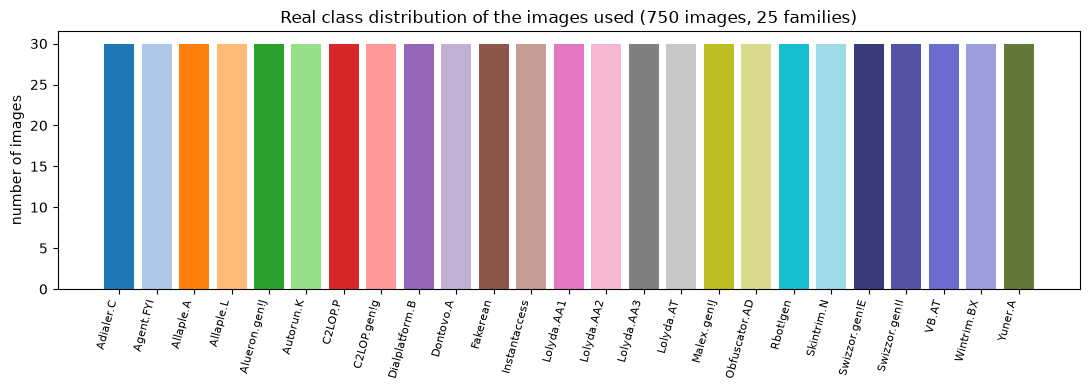

In [5]:
print("dataset: Malimg (Nataraj et al. 2011), mirror", HF_REPO if DATA_SOURCE == "hf" else LOCAL_DIR)
print("array shape (images, height, width):", X_all.shape, "| dtype", X_all.dtype, "| pixel range", int(X_all.min()), "-", int(X_all.max()))
print("features: the", IMG * IMG, "pixels of each", IMG, "x", IMG, "grey-scale image (no tabular feature names)")
print("original labels = malware family names (folder names):")
counts = pd.Series(y_all).map(dict(enumerate(FAMILIES))).value_counts().reindex(FAMILIES)
split_counts = pd.DataFrame({"all": counts.values,
                             "train": np.bincount(ytr.numpy(), minlength=NUM_CLASSES),
                             "val": np.bincount(yva.numpy(), minlength=NUM_CLASSES),
                             "test": np.bincount(yte.numpy(), minlength=NUM_CLASSES)}, index=FAMILIES)
display(split_counts)

# 25 distinguishable colours for the families, reused in every figure
FAM_COLORS = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors[:5])
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(NUM_CLASSES), counts.values, color=FAM_COLORS[:NUM_CLASSES])
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(FAMILIES, rotation=75, ha="right", fontsize=8)
ax.set_ylabel("number of images"); ax.set_title(f"Real class distribution of the images used ({len(y_all)} images, {NUM_CLASSES} families)")
plt.tight_layout(); plt.show()

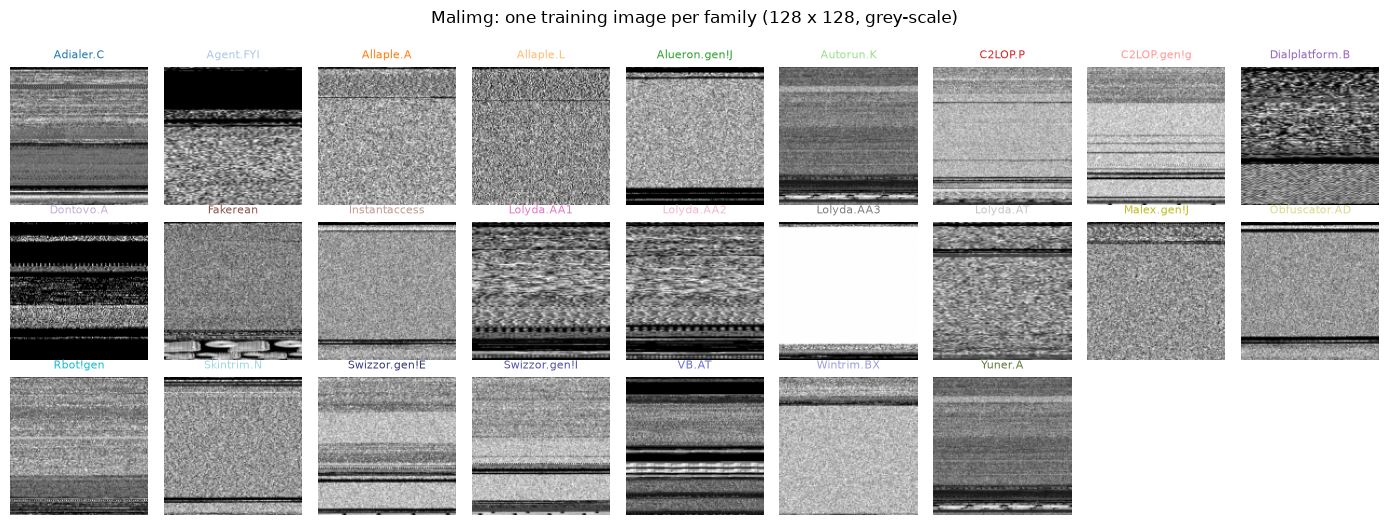

In [6]:
# One real example per family (training split), so that "what the model sees" is concrete.
fig, axes = plt.subplots(3, 9, figsize=(14, 5.2))
for ax in axes.ravel(): ax.axis("off")
for c in range(NUM_CLASSES):
    j = int(np.where(ytr.numpy() == c)[0][0])
    ax = axes.ravel()[c]; ax.imshow(Xtr[j].numpy(), cmap="gray"); ax.set_title(FAMILIES[c], fontsize=8, color=FAM_COLORS[c]); ax.axis("off")
plt.suptitle("Malimg: one training image per family (128 x 128, grey-scale)", y=1.0); plt.tight_layout(); plt.show()

PCA explained variance ratio of the first two components: [0.363 0.135]


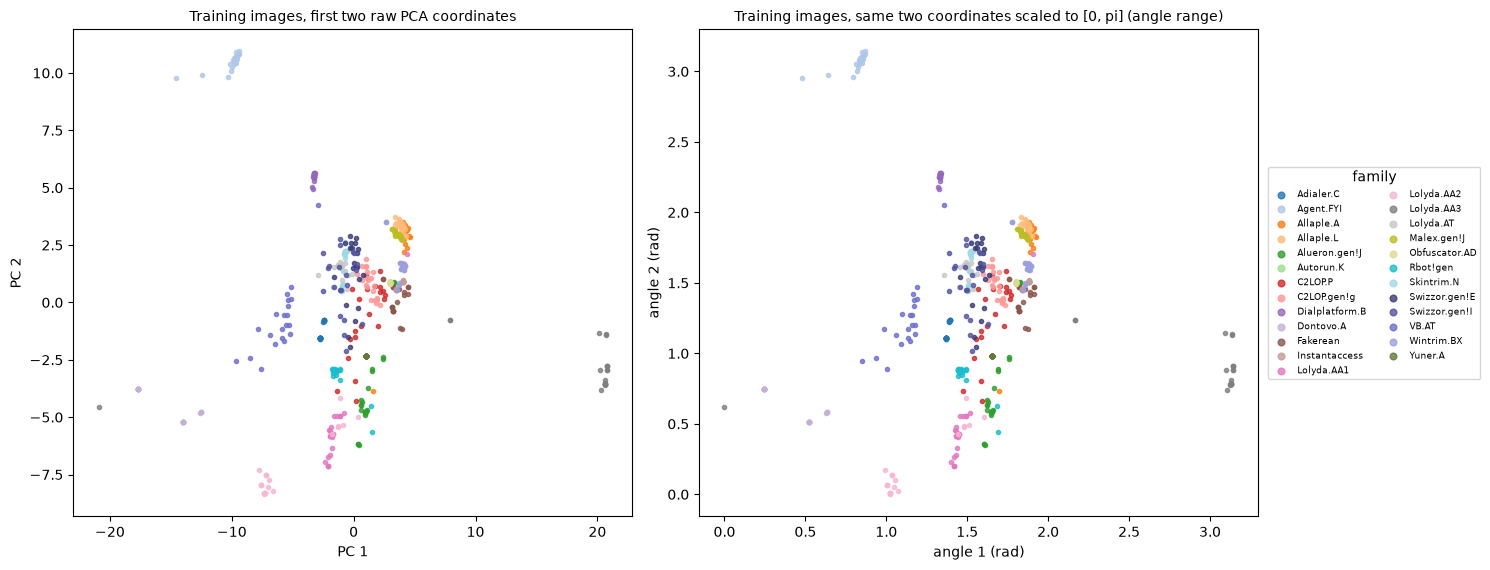

Each point is one real malware image. Note the dense, partly overlapping clusters: a linear 2-D view cannot separate
25 families, which is why the paper uses a CNN to learn a 6-D latent code instead of PCA.


In [7]:
# 2-D projection of the REAL training images, coloured by their ground-truth family.
# PCA is fitted on the training split only (pixels down-sampled to 64 x 64 to save memory), then applied to val / test.
def small(Xu8): return F.avg_pool2d(Xu8.float().unsqueeze(1) / 255.0, 2).flatten(1).numpy()
pca_pix = PCA(n_components=2, svd_solver="randomized", random_state=SEED).fit(small(Xtr))
P_tr, P_te = pca_pix.transform(small(Xtr)), pca_pix.transform(small(Xte))
print("PCA explained variance ratio of the first two components:", np.round(pca_pix.explained_variance_ratio_, 3))
sc = MinMaxScaler((0, np.pi)).fit(P_tr)                      # same recipe as the reference notebooks, fitted on train only
A_tr, A_te = sc.transform(P_tr), np.clip(sc.transform(P_te), 0, np.pi)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, (A, title) in zip(axes, [(P_tr, "Training images, first two raw PCA coordinates"),
                                  (A_tr, "Training images, same two coordinates scaled to [0, pi] (angle range)")]):
    for c in range(NUM_CLASSES):
        m = ytr.numpy() == c
        ax.scatter(A[m, 0], A[m, 1], s=9, color=FAM_COLORS[c], label=FAMILIES[c], alpha=0.8)
    ax.set_title(title, fontsize=10); ax.set_xlabel("PC 1" if A is P_tr else "angle 1 (rad)"); ax.set_ylabel("PC 2" if A is P_tr else "angle 2 (rad)")
axes[1].legend(ncol=2, fontsize=6.5, markerscale=1.6, loc="center left", bbox_to_anchor=(1.01, 0.5), title="family")
plt.tight_layout(); plt.show()
print("Each point is one real malware image. Note the dense, partly overlapping clusters: a linear 2-D view cannot separate")
print("25 families, which is why the paper uses a CNN to learn a 6-D latent code instead of PCA.")
del P_tr, P_te, A_tr, A_te

## 2. The quantum layer: the PennyLane circuit and its exact PyTorch twin

The quantum layer is defined **once, as a PennyLane QNode** (`quantum_circuit`), exactly as in the paper (Section 3.4): `n = 6` qubits start in |0>; **angle encoding** applies `RY(z_i)` to qubit `i` with `z = tanh(CNN output)`; then each of `L = 6` variational layers applies a trainable `RY(theta_{l,i})` on every qubit followed by the **linear CNOT chain** `0->1, 1->2, ..., 4->5`; finally the six Pauli-Z expectation values `<Z_i>` are returned. That is 6 + 36 = 42 RY gates and 30 CNOTs (the "42 RY" of Fig. 3).

**Why a twin?** A PennyLane QNode costs about 0.2 s per forward/backward call *regardless of batch size* (Python overhead of 72 gates). Adversarial training needs about 11 quantum passes per mini-batch, i.e. several seconds per batch, which is not feasible on a CPU. Because the circuit contains only RY and CNOT gates, its state vector is real and can be simulated exactly with tensor products and a fixed permutation in plain PyTorch (`fast_forward`). We use that twin **only for training**; the next cell asserts that it matches the PennyLane QNode in value and in gradients (to 1e-12 in float64), and **every number reported in the result tables is computed with the PennyLane QNode itself** (`model.backend = "pennylane"`).

In [8]:
# ---------- (a) reference circuit: PennyLane QNode ----------
dev = qml.device("default.qubit", wires=N_QUBITS)

def entangler_pairs(n, ring=False):
    return [(i, i + 1) for i in range(n - 1)] + ([(n - 1, 0)] if ring else [])

def make_qnode(ring=False):
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        for i in range(N_QUBITS):                       # angle encoding of the 6 latent numbers
            qml.RY(inputs[..., i], wires=i)
        for l in range(weights.shape[0]):               # variational layers
            for i in range(N_QUBITS):
                qml.RY(weights[l, i], wires=i)
            for c, t in entangler_pairs(N_QUBITS, ring):# linear CNOT chain (ring only for the ablation)
                qml.CNOT(wires=[c, t])
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
    return circuit

quantum_circuit = make_qnode(ring=False)

def pl_forward(inputs, weights, ring=False):
    qn = quantum_circuit if not ring else make_qnode(True)
    return torch.stack(qn(inputs, weights), dim=-1).to(inputs.dtype)

# ---------- (b) exact PyTorch twin of the same gate list ----------
def _perm(n, pairs):
    idx = np.arange(2 ** n)
    b = (idx[:, None] >> np.arange(n - 1, -1, -1)) & 1          # wire 0 = most significant bit (PennyLane convention)
    for c, t in pairs:                                           # apply CNOTs one after the other to the basis labels
        b[:, t] ^= b[:, c]
    return (b * (1 << np.arange(n - 1, -1, -1))).sum(1)         # amplitude j moves to position new[j]
_SIGN = torch.tensor(1.0 - 2.0 * ((np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS - 1, -1, -1)) & 1), dtype=torch.float32)
_INV = {}

def _ry(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)

def fast_forward(inputs, weights, ring=False):
    B = inputs.shape[0]
    c, s = torch.cos(inputs / 2), torch.sin(inputs / 2)
    psi = torch.stack([c[:, 0], s[:, 0]], -1)                    # product state of the RY encoding
    for i in range(1, N_QUBITS):
        q = torch.stack([c[:, i], s[:, i]], -1)
        psi = (psi[:, :, None] * q[:, None, :]).reshape(B, -1)
    if ring not in _INV:
        _INV[ring] = torch.as_tensor(np.argsort(_perm(N_QUBITS, entangler_pairs(N_QUBITS, ring))))
    inv = _INV[ring]
    for l in range(weights.shape[0]):
        K = _ry(weights[l, 0])
        for i in range(1, N_QUBITS):
            K = torch.kron(K, _ry(weights[l, i]))               # RY on every qubit = Kronecker product
        psi = (psi @ K.T)[:, inv]                                # then the CNOT chain = a fixed permutation
    return (psi ** 2) @ _SIGN.to(psi.dtype)                      # <Z_i> = sum_x p(x) (-1)^{x_i}

## Quantum Circuit Architecture

The figure below is drawn with `qml.draw_mpl` **from the very QNode `quantum_circuit`** that the hybrid model executes when it is evaluated (all result tables use it). It shows the encoding (first column of 6 RY gates), the trainable RY gates, the CNOT chain and the six Pauli-Z read-outs. The circuit is shown for one illustrative input / weight vector; the structure does not depend on the values.

Assumptions where the paper is silent (also listed in the table above): trainable weights are initialised uniformly in [0, 2 pi) (PennyLane `TorchLayer` default, as in the authors' code); the CNOT chain has no ring closure (the ring variant is only used in the ablation, where it lowers accuracy in the paper too); no measurement shots (exact expectation values); the 6-D latent code is squashed by `tanh` before being used as RY angles, so the encoding angles lie in [-1, 1] rad. The paper's "circuit depth = 6" counts variational layers; the true gate depth is printed below.

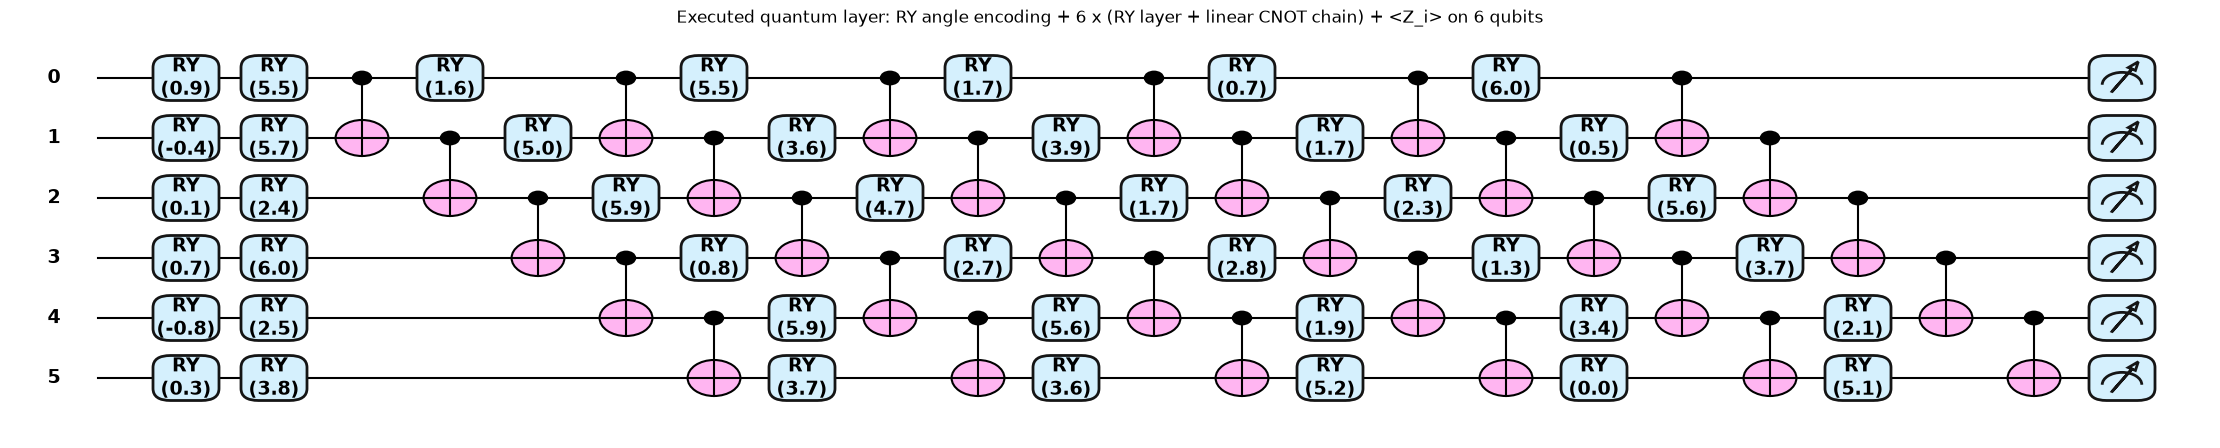

qubits                    : 6
gate counts               : {'RY': 42, 'CNOT': 30}
circuit depth (true)      : 22 | variational layers L = 6 (the paper's 'depth = 6')
trainable parameters      : 36 (= L x n = 6 x 6 )  + 6 non-trainable encoding angles
RY gates: 42 (6 encoding + 36 trainable)  CNOT gates: 30 (= 5 per layer x 6 layers)


linear CNOT pattern: PennyLane vs PyTorch twin, max |difference| over outputs and gradients = 5.1e-15
ring   CNOT pattern: PennyLane vs PyTorch twin, max |difference| over outputs and gradients = 1.6e-15


In [9]:
ex_in = torch.tensor([0.9, -0.4, 0.1, 0.7, -0.8, 0.3])                       # illustrative latent code
ex_w = torch.rand(Q_LAYERS, N_QUBITS, generator=torch.Generator().manual_seed(SEED)) * 2 * math.pi
fig, ax = qml.draw_mpl(quantum_circuit, decimals=1, style="pennylane")(ex_in, ex_w)
fig.set_size_inches(22, 4.2); fig.suptitle("Executed quantum layer: RY angle encoding + 6 x (RY layer + linear CNOT chain) + <Z_i> on 6 qubits", y=1.02)
plt.show()

specs = qml.specs(quantum_circuit)(ex_in, ex_w)
res = specs["resources"] if isinstance(specs, dict) else specs.resources
n_cnot = res.gate_types.get("CNOT", 0); n_ry = res.gate_types.get("RY", 0)
print("qubits                    :", N_QUBITS)
print("gate counts               :", dict(res.gate_types))
print("circuit depth (true)      :", res.depth, "| variational layers L =", Q_LAYERS, "(the paper's 'depth = 6')")
print("trainable parameters      :", ex_w.numel(), "(= L x n =", Q_LAYERS, "x", N_QUBITS, ")  + 6 non-trainable encoding angles")
print("RY gates:", n_ry, "(6 encoding + 36 trainable)  CNOT gates:", n_cnot, "(= 5 per layer x 6 layers)")
N_CNOT_REAL = n_cnot

# --- equivalence of the PennyLane circuit and the PyTorch twin (value and gradients), float64 ---
g = torch.Generator().manual_seed(0)
for ring in (False, True):
    w64 = (torch.rand(Q_LAYERS, N_QUBITS, generator=g, dtype=torch.float64) * 2 * math.pi).requires_grad_(True)
    x64 = (torch.rand(8, N_QUBITS, generator=g, dtype=torch.float64) * 2 - 1).requires_grad_(True)
    a, b = pl_forward(x64, w64, ring), fast_forward(x64, w64, ring)
    ga = torch.autograd.grad(a.pow(2).sum(), [x64, w64]); gb = torch.autograd.grad(b.pow(2).sum(), [x64, w64])
    err = max((a - b).abs().max().item(), *[(u - v).abs().max().item() for u, v in zip(ga, gb)])
    assert err < 1e-10, err
    print(f"{'ring  ' if ring else 'linear'} CNOT pattern: PennyLane vs PyTorch twin, max |difference| over outputs and gradients = {err:.1e}")

## 3. The hybrid model: CNN -> quantum layer -> MLP head

`HybridQNN(quantum=True)` is the paper's network. `HybridQNN(quantum=False)` is the **classical CNN of the same architecture** that the paper compares against (RQ1): the 6 CNN outputs go straight into the MLP head instead of through the circuit. The helper functions implement the attacks (FGSM: one step of size 0.03; PGD: 7 steps of 0.01 inside an eps = 0.1 ball with a random start; both in the normalised [-1, 1] pixel space of the paper's code) and the QNI-CCP perturbation of Eqs. 1-8:

`z' = z + eps_q * ( S (.) (mu_{c'} - z) )`, `S = dLoss/dz`, `c'` a random class different from the label, `eps_q = 1 / (1 + alpha N_CNOT + beta D)`.

In [10]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=1.5):                 # CHOICE: gamma = 1.5 (authors' baseline notebook)
        super().__init__(); self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction="none")
        return (self.alpha * (1 - torch.exp(-ce)) ** self.gamma * ce).mean()

class FeatureReduce(nn.Module):
    """5 strided 3x3 convs (8-16-32-64-128), BatchNorm, ReLU, dropout, global average pooling, FC -> n_qubits."""
    def __init__(self, final_dim, dropout=0.4):
        super().__init__()
        ch, blocks = [1, 8, 16, 32, 64, 128], []
        for i in range(5):
            blocks += [nn.Conv2d(ch[i], ch[i + 1], 3, stride=2, padding=1), nn.BatchNorm2d(ch[i + 1]), nn.ReLU()]
            if i < 4: blocks.append(nn.Dropout(dropout))
        blocks.append(nn.AdaptiveAvgPool2d((1, 1)))
        self.conv, self.fc = nn.Sequential(*blocks), nn.Linear(128, final_dim)
    def forward(self, x): return self.fc(self.conv(x).flatten(1))

class HybridQNN(nn.Module):
    def __init__(self, quantum=True, q_layers=Q_LAYERS, ring=False):
        super().__init__()
        self.quantum, self.backend, self.ring = quantum, "fast", ring
        self.feature_extractor = FeatureReduce(N_QUBITS)
        if quantum:                                            # CHOICE: U[0, 2 pi) initial weights = TorchLayer default
            self.q_weights = nn.Parameter(torch.rand(q_layers, N_QUBITS) * 2 * math.pi)
        self.classifier = nn.Sequential(nn.Linear(N_QUBITS, 64), nn.ReLU(), nn.Dropout(0.3),
                                        nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
                                        nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, NUM_CLASSES))
    def latent(self, x): return torch.tanh(self.feature_extractor(x))        # the angles that enter the circuit
    def q_layer(self, f):
        if not self.quantum: return f
        return fast_forward(f, self.q_weights, self.ring) if self.backend == "fast" else pl_forward(f, self.q_weights, self.ring)
    def head(self, f): return self.classifier(self.q_layer(f))
    def forward(self, x): return self.head(self.latent(x))

class eval_mode:                                              # attacks run in eval() mode; training mode is restored afterwards
    def __init__(self, m): self.m = m
    def __enter__(self): self.was = self.m.training; self.m.eval()
    def __exit__(self, *a): self.m.train(self.was)

def prep(xb): return ((xb.float() / 255.0 - 0.5) / 0.5).unsqueeze(1)          # uint8 (B,H,W) -> [-1,1], (B,1,H,W)

def fgsm_attack(model, x, y, eps=EPS_FGSM):
    with eval_mode(model):
        xa = x.clone().detach().requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(xa), y), xa)
    return torch.clamp(x + eps * g.sign(), -1, 1).detach()

def pgd_attack(model, x, y, eps=EPS_PGD, alpha=ALPHA_PGD, iters=ITERS_PGD):
    with eval_mode(model):
        xa = torch.clamp(x + torch.empty_like(x).uniform_(-eps, eps), -1, 1).detach()      # random start in the eps-ball
        for _ in range(iters):
            xa.requires_grad_(True)
            g, = torch.autograd.grad(F.cross_entropy(model(xa), y), xa)
            xa = xa.detach() + alpha * g.sign()
            xa = torch.clamp(x + torch.clamp(xa - x, -eps, eps), -1, 1).detach()
    return xa

@torch.no_grad()
def class_centroids(model, X, y, batch=128):                   # Eq. 3: mean latent vector per class (training split)
    with eval_mode(model):
        feats = torch.cat([model.latent(prep(X[i:i + batch])) for i in range(0, len(X), batch)])
    cen = torch.zeros(NUM_CLASSES, feats.shape[1])
    for c in range(NUM_CLASSES):
        if (y == c).any(): cen[c] = feats[y == c].mean(0)
    return cen

def eps_quantum(n_cnot=30, depth=6, alpha=ALPHA_Q, beta=BETA_Q):   # Eq. 6; CHOICE: N_CNOT = 30, D = 6 as in the authors' code
    return 1.0 / (1.0 + alpha * n_cnot + beta * depth)

def qni_ccp_features(model, feats, y, centroids, eps_q, gen):
    with eval_mode(model):
        z = feats.detach().clone().requires_grad_(True)
        S, = torch.autograd.grad(F.cross_entropy(model.head(z), y), z)         # Eq. 1: sensitivity of the loss to each latent number
    tgt = (y + torch.randint(1, NUM_CLASSES, y.shape, generator=gen)) % NUM_CLASSES   # random class != true class (Sec. 3.3.3)
    z0 = feats.detach()
    return (z0 + eps_q * S * (centroids[tgt] - z0)).detach()                    # Eqs. 5, 7, 8

def augment(x, gen):                                           # training augmentation of the authors' code: flip + rotation +-10 deg
    B = x.shape[0]
    x = torch.where((torch.rand(B, generator=gen) < 0.5)[:, None, None, None], x.flip(-1), x)
    ang = (torch.rand(B, generator=gen) * 20 - 10) * math.pi / 180
    cs, sn, z0 = torch.cos(ang), torch.sin(ang), torch.zeros(B)
    grid = F.affine_grid(torch.stack([torch.stack([cs, -sn, z0], 1), torch.stack([sn, cs, z0], 1)], 1), x.shape, align_corners=False)
    return F.grid_sample(x + 1, grid, padding_mode="zeros", align_corners=False) - 1   # black (= -1) fill

@torch.no_grad()
def predict(model, X, batch=256, return_probs=False):
    with eval_mode(model):
        out = torch.cat([model(prep(X[i:i + batch])) for i in range(0, len(X), batch)])
    p = out.softmax(-1)
    return (p.argmax(-1), p) if return_probs else p.argmax(-1)

def accuracy(model, X, y): return (predict(model, X) == y).float().mean().item()

def train_model(model, mode, epochs, seed=SEED, lr=LR, tag=""):
    """mode: 'basic' = focal loss | 'qni' = 0.7 clean + 0.2 QNI + 0.1 centroid | 'qslp' = Algorithm 1 (QNI-CCP + FGSM + PGD)."""
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-3)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, "min", patience=5)
    focal, epsq = FocalLoss(), eps_quantum()
    best, best_state, hist = -1.0, None, []
    cen = class_centroids(model, Xtr, ytr) if mode != "basic" else None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        if mode != "basic" and ep % CENTROID_EVERY == 0: cen = class_centroids(model, Xtr, ytr)
        model.train()
        perm = torch.randperm(len(Xtr), generator=gen)
        tl = tc = tn = 0
        for i in range(0, len(perm) - BATCH + 1, BATCH):          # last incomplete batch dropped (BatchNorm safety)
            idx = perm[i:i + BATCH]
            xb, yb = augment(prep(Xtr[idx]), gen), ytr[idx]
            feats = model.latent(xb); logits = model.head(feats)
            if mode == "basic":
                loss = focal(logits, yb)
            else:
                l_clean = F.cross_entropy(logits, yb)
                l_qni = F.cross_entropy(model.head(qni_ccp_features(model, feats, yb, cen, epsq, gen)), yb)
                creg = ((feats - cen[yb]) ** 2).mean()
                if mode == "qni":
                    loss = 0.7 * l_clean + 0.2 * l_qni + 0.1 * creg
                else:
                    xf, xp = fgsm_attack(model, xb, yb), pgd_attack(model, xb, yb, iters=ITERS_PGD_TRAIN)
                    loss = (0.5 * l_clean + 0.15 * l_qni + 0.10 * F.cross_entropy(model(xf), yb)
                            + 0.15 * F.cross_entropy(model(xp), yb) + 0.10 * creg)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item() * len(idx); tc += (logits.argmax(1) == yb).sum().item(); tn += len(idx)
        sched.step(tl / tn)
        va = accuracy(model, Xva, yva)
        hist.append(dict(epoch=ep, loss=tl / tn, train_acc=tc / tn, val_acc=va, seconds=time.time() - t0))
        if va > best: best, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{tag or mode}] epoch {ep:2d}/{epochs}  loss {tl / tn:.4f}  train acc {tc / tn:.3f}  val acc {va:.3f}  ({time.time() - t0:.0f}s)", flush=True)
    model.load_state_dict(best_state)                              # best-validation checkpoint (as in the authors' code)
    return pd.DataFrame(hist)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
_m = HybridQNN(True)
print(f"hybrid model: {n_params(_m):,} trainable parameters = CNN {n_params(_m.feature_extractor):,} + quantum {_m.q_weights.numel()} + MLP head {n_params(_m.classifier):,}")
print(f"classical twin: {n_params(HybridQNN(False)):,} trainable parameters | eps_q (Eq. 6, N_CNOT=30, D=6) = {eps_quantum():.4f}"
      f" | with the true depth printed above: {eps_quantum(N_CNOT_REAL, res.depth):.4f}")
del _m

hybrid model: 103,027 trainable parameters = CNN 99,510 + quantum 36 + MLP head 3,481
classical twin: 102,991 trainable parameters | eps_q (Eq. 6, N_CNOT=30, D=6) = 0.0270 | with the true depth printed above: 0.0189


## 4. Training the five stages

All models start from scratch with the same seed and see exactly the same data. In order:

1. **Hybrid basic** (Table 5, "Hybrid QNN"): CNN + quantum layer + head, focal loss.
2. **Classical basic** (the paper's "Classical CNN"): same network without the circuit.
3. **QNI-CCP** (Table 5, "After QNI-CCP"): hybrid with latent-space class-centre perturbation.
4. **QSLP, "M1"** (Table 5 "After Adv training", Table 7 "Adv training M1"): hybrid trained from scratch with Algorithm 1 (QNI-CCP + FGSM + PGD). The classical network gets the same adversarial recipe for comparison.
5. **"M2"** (Table 7): the *basic* models are first trained normally, then fine-tuned with the adversarial loss.

The checkpoint with the best validation accuracy is kept. Training uses the fast exact simulator of the circuit (see section 2). Each epoch prints its loss, training accuracy and validation accuracy.

In [11]:
MODELS, HIST = {}, {}
t_all = time.time()

def run(name, quantum, mode, epochs, init=None, seed=SEED):
    torch.manual_seed(seed)
    m = HybridQNN(quantum)
    if init is not None: m.load_state_dict(copy.deepcopy(MODELS[init].state_dict()))
    t0 = time.time()
    HIST[name] = train_model(m, mode, epochs, seed=seed, tag=name)
    HIST[name].attrs["seconds"] = time.time() - t0
    MODELS[name] = m
    print(f"== {name}: best val acc {HIST[name].val_acc.max():.3f}, {time.time() - t0:.0f}s\n")

run("H0 hybrid basic",      True,  "basic", EPOCHS["basic"])
run("C0 classical basic",   False, "basic", EPOCHS["basic"])
run("H1 hybrid QNI-CCP",    True,  "qni",   EPOCHS["qni"])
run("H2 hybrid QSLP (M1)",  True,  "qslp",  EPOCHS["qslp"])
run("C2 classical adv (M1)", False, "qslp",  EPOCHS["qslp"])
run("H3 hybrid basic+adv (M2)",   True,  "qslp", EPOCHS["finetune"], init="H0 hybrid basic")
run("C3 classical basic+adv (M2)", False, "qslp", EPOCHS["finetune"], init="C0 classical basic")
print(f"total training time {(time.time() - t_all) / 60:.1f} min")

[H0 hybrid basic] epoch  1/30  loss 3.0328  train acc 0.029  val acc 0.036  (21s)


[H0 hybrid basic] epoch  2/30  loss 2.9677  train acc 0.055  val acc 0.089  (14s)


[H0 hybrid basic] epoch  3/30  loss 2.7202  train acc 0.080  val acc 0.098  (11s)


[H0 hybrid basic] epoch  4/30  loss 2.5621  train acc 0.078  val acc 0.080  (7s)


[H0 hybrid basic] epoch  5/30  loss 2.5118  train acc 0.072  val acc 0.116  (5s)


...

[C3 classical basic+adv (M2)] epoch  1/4  loss 1.6135  train acc 0.387  val acc 0.545  (33s)


[C3 classical basic+adv (M2)] epoch  2/4  loss 1.5346  train acc 0.336  val acc 0.571  (27s)


[C3 classical basic+adv (M2)] epoch  3/4  loss 1.5790  train acc 0.330  val acc 0.491  (38s)


[C3 classical basic+adv (M2)] epoch  4/4  loss 1.5507  train acc 0.373  val acc 0.518  (24s)


== C3 classical basic+adv (M2): best val acc 0.571, 124s

total training time 32.0 min


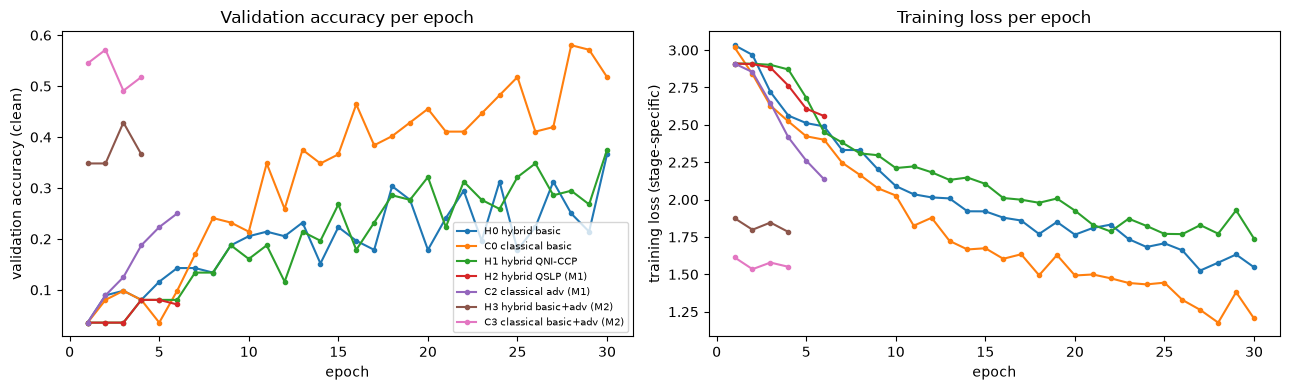

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, h in HIST.items():
    ax[0].plot(h.epoch, h.val_acc, marker="o", ms=3, label=name); ax[1].plot(h.epoch, h.loss, marker="o", ms=3, label=name)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation accuracy (clean)"); ax[0].set_title("Validation accuracy per epoch")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss (stage-specific)"); ax[1].set_title("Training loss per epoch")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 5. Metrics: clean accuracy and robustness to FGSM / PGD

Every model is evaluated on the **held-out test split** with three inputs: clean images, FGSM images (eps = 0.03) and PGD images (eps = 0.1, step 0.01, 7 iterations, random start). The attacks are white-box: they differentiate through the model that is being tested. For the hybrid models the attack gradients flow through the **PennyLane circuit itself** (`model.backend = "pennylane"`); a clean-accuracy cross-check against the fast simulator is printed. Because Malimg is imbalanced, macro-F1 (every family counts equally) is reported next to accuracy; the standard error of an accuracy is `sqrt(p(1-p)/n)` for `n` test images, which is large for small test sets.

In [13]:
def f1_per_class(y, p): return f1_score(y, p, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)

def evaluate_model(name, X, y, batch=128, seed=SEED):
    m = MODELS[name]
    out = {}
    if m.quantum:                                                    # cross-check: fast simulator vs PennyLane on clean data
        m.backend = "fast"; p_fast = predict(m, X)
    m.backend = "pennylane" if m.quantum else "fast"
    p_clean = predict(m, X)
    if m.quantum: out["fast_vs_pennylane_agreement"] = (p_fast == p_clean).float().mean().item()
    torch.manual_seed(seed)
    preds = {"clean": p_clean}
    for key, atk in (("fgsm", lambda xb, yb: fgsm_attack(m, xb, yb, EPS_FGSM)),
                     ("pgd", lambda xb, yb: pgd_attack(m, xb, yb, EPS_PGD, ALPHA_PGD, ITERS_PGD))):
        P = []
        for i in range(0, len(X), batch):
            xa = atk(prep(X[i:i + batch]), y[i:i + batch])
            with torch.no_grad(), eval_mode(m): P.append(m(xa).argmax(1))
        preds[key] = torch.cat(P)
    for key, p in preds.items():
        out[f"acc_{key}"] = (p == y).float().mean().item()
        out[f"f1m_{key}"] = f1_score(y, p, average="macro", zero_division=0)
        out[f"f1w_{key}"] = f1_score(y, p, average="weighted", zero_division=0)
        out[f"f1c_{key}"] = f1_per_class(y, p)
        out[f"pred_{key}"] = p.numpy()
    m.backend = "fast"
    return out

t0 = time.time()
EVAL, VAL = {}, {}
for name in MODELS:
    EVAL[name] = evaluate_model(name, Xte, yte)
    m = MODELS[name]; m.backend = "pennylane" if m.quantum else "fast"; VAL[name] = accuracy(m, Xva, yva); m.backend = "fast"
    print(f"{name:30s} test acc clean {EVAL[name]['acc_clean']:.3f} | FGSM {EVAL[name]['acc_fgsm']:.3f} | PGD {EVAL[name]['acc_pgd']:.3f}"
          + (f"   (fast simulator agrees with PennyLane on {EVAL[name]['fast_vs_pennylane_agreement']:.1%} of clean predictions)" if "fast_vs_pennylane_agreement" in EVAL[name] else ""))
print(f"evaluation time {time.time() - t0:.0f}s")

n_te = len(yte)
se = lambda p: 100 * math.sqrt(max(p * (1 - p), 1e-12) / n_te)
tab5 = pd.DataFrame({name: {"val acc": VAL[name], "test acc": e["acc_clean"], "F1 macro": e["f1m_clean"], "F1 weighted": e["f1w_clean"],
                            "precision macro": precision_score(yte, e["pred_clean"], average="macro", zero_division=0),
                            "recall macro": recall_score(yte, e["pred_clean"], average="macro", zero_division=0)} for name, e in EVAL.items()}).T
print("\nTable 5 style: clean performance of every stage (Malimg, test split n = %d; accuracy standard error about +-%.1f points)" % (n_te, se(0.9)))
display(tab5.round(3))
tab7 = pd.DataFrame({name: {"clean acc %": 100 * e["acc_clean"], "FGSM acc %": 100 * e["acc_fgsm"], "PGD acc %": 100 * e["acc_pgd"],
                            "clean F1 macro %": 100 * e["f1m_clean"], "FGSM F1 macro %": 100 * e["f1m_fgsm"], "PGD F1 macro %": 100 * e["f1m_pgd"]} for name, e in EVAL.items()}).T
print("Table 7 / Fig. 6 style: robustness (percent)")
display(tab7.round(1))

H0 hybrid basic                test acc clean 0.354 | FGSM 0.142 | PGD 0.080   (fast simulator agrees with PennyLane on 100.0% of clean predictions)


C0 classical basic             test acc clean 0.566 | FGSM 0.124 | PGD 0.080


H1 hybrid QNI-CCP              test acc clean 0.389 | FGSM 0.168 | PGD 0.080   (fast simulator agrees with PennyLane on 100.0% of clean predictions)


H2 hybrid QSLP (M1)            test acc clean 0.080 | FGSM 0.080 | PGD 0.080   (fast simulator agrees with PennyLane on 100.0% of clean predictions)


C2 classical adv (M1)          test acc clean 0.221 | FGSM 0.204 | PGD 0.142


H3 hybrid basic+adv (M2)       test acc clean 0.407 | FGSM 0.204 | PGD 0.133   (fast simulator agrees with PennyLane on 100.0% of clean predictions)


C3 classical basic+adv (M2)    test acc clean 0.496 | FGSM 0.265 | PGD 0.124
evaluation time 35s

Table 5 style: clean performance of every stage (Malimg, test split n = 113; accuracy standard error about +-2.8 points)


,val acc,test acc,F1 macro,F1 weighted,precision macro,recall macro
H0 hybrid basic,0.366,0.354,0.279,0.267,0.280,0.370
C0 classical basic,0.580,0.566,0.482,0.479,0.474,0.566
H1 hybrid QNI-CCP,0.375,0.389,0.297,0.293,0.307,0.398
H2 hybrid QSLP (M1),0.080,0.080,0.015,0.014,0.008,0.080
C2 classical adv (M1),0.250,0.221,0.127,0.120,0.105,0.228
H3 hybrid basic+adv (M2),0.429,0.407,0.318,0.313,0.296,0.418
C3 classical basic+adv (M2),0.571,0.496,0.429,0.421,0.441,0.510


Table 7 / Fig. 6 style: robustness (percent)


,clean acc %,FGSM acc %,PGD acc %,clean F1 macro %,FGSM F1 macro %,PGD F1 macro %
H0 hybrid basic,35.4,14.2,8.0,27.9,7.3,3.2
C0 classical basic,56.6,12.4,8.0,48.2,9.1,5.7
H1 hybrid QNI-CCP,38.9,16.8,8.0,29.7,9.1,6.9
H2 hybrid QSLP (M1),8.0,8.0,8.0,1.5,1.6,1.6
C2 classical adv (M1),22.1,20.4,14.2,12.7,11.4,7.6
H3 hybrid basic+adv (M2),40.7,20.4,13.3,31.8,11.7,4.9
C3 classical basic+adv (M2),49.6,26.5,12.4,42.9,21.5,10.0


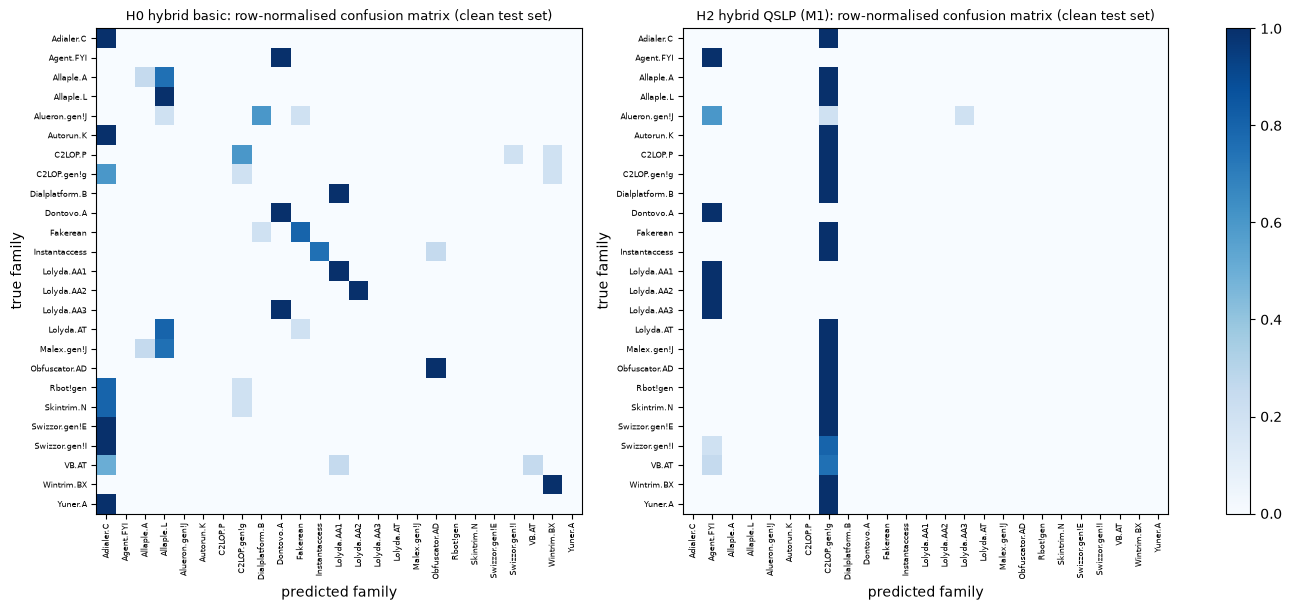

                precision    recall  f1-score   support

     Adialer.C       0.00      0.00      0.00         4
     Agent.FYI       0.15      1.00      0.27         4
     Allaple.A       0.00      0.00      0.00         4
     Allaple.L       0.00      0.00      0.00         5
 Alueron.gen!J       0.00      0.00      0.00         5
     Autorun.K       0.00      0.00      0.00         4
       C2LOP.P       0.00      0.00      0.00         5
   C2LOP.gen!g       0.06      1.00      0.11         5
Dialplatform.B       0.00      0.00      0.00         4
     Dontovo.A       0.00      0.00      0.00         4
      Fakerean       0.00      0.00      0.00         5
 Instantaccess       0.00      0.00      0.00         4
    Lolyda.AA1       0.00      0.00      0.00         4
    Lolyda.AA2       0.00      0.00      0.00         4
    Lolyda.AA3       0.00      0.00      0.00         5
     Lolyda.AT       0.00      0.00      0.00         5
   Malex.gen!J       0.00      0.00      0.00  

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.3))
for ax, name in zip(axes, ["H0 hybrid basic", "H2 hybrid QSLP (M1)"]):
    cm = confusion_matrix(yte, EVAL[name]["pred_clean"], labels=list(range(NUM_CLASSES))).astype(float)
    cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(FAMILIES, rotation=90, fontsize=6); ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(FAMILIES, fontsize=6)
    ax.set_xlabel("predicted family"); ax.set_ylabel("true family"); ax.set_title(f"{name}: row-normalised confusion matrix (clean test set)", fontsize=9)
plt.colorbar(im, ax=axes, fraction=0.025); plt.show()
print(classification_report(yte, EVAL["H2 hybrid QSLP (M1)"]["pred_clean"], labels=list(range(NUM_CLASSES)), target_names=FAMILIES, zero_division=0, digits=2))

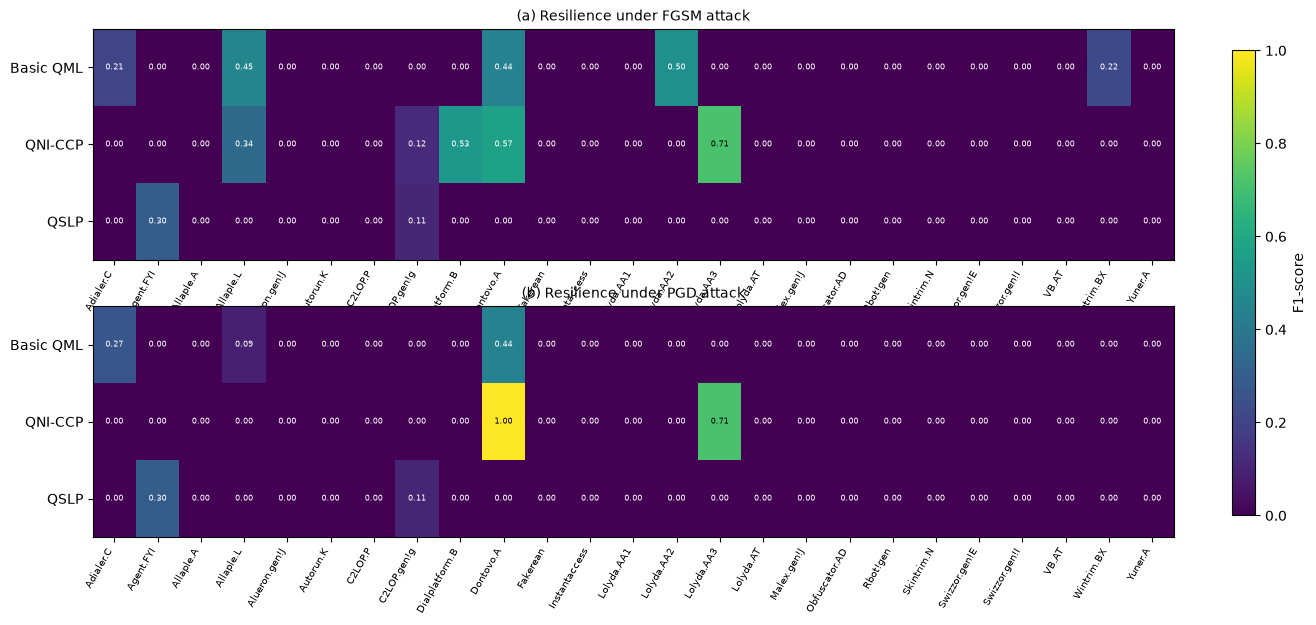

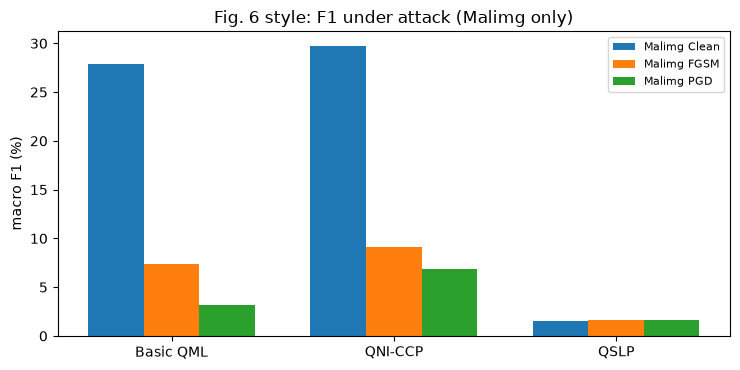

In [15]:
# Fig. 5 of the paper: class-wise F1 under FGSM and PGD for the three hybrid stages (Basic QML, QNI-CCP, QSLP)
trio = [("Basic QML", "H0 hybrid basic"), ("QNI-CCP", "H1 hybrid QNI-CCP"), ("QSLP", "H2 hybrid QSLP (M1)")]
fig, axes = plt.subplots(2, 1, figsize=(15, 6.6))
for ax, key, title in zip(axes, ["fgsm", "pgd"], ["(a) Resilience under FGSM attack", "(b) Resilience under PGD attack"]):
    M = np.stack([EVAL[n][f"f1c_{key}"] for _, n in trio])
    im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_yticks(range(3)); ax.set_yticklabels([t for t, _ in trio]); ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(FAMILIES, rotation=60, ha="right", fontsize=7)
    for i in range(3):
        for j in range(NUM_CLASSES): ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=5.5, color="white" if M[i, j] < 0.6 else "black")
    ax.set_title(title, fontsize=10)
fig.colorbar(im, ax=axes, fraction=0.02, label="F1-score"); plt.show()

# Fig. 6: overall macro-F1 under clean / FGSM / PGD
fig, ax = plt.subplots(figsize=(7.5, 3.8)); w = 0.25
for k, (cond, key) in enumerate([("Clean", "clean"), ("FGSM", "fgsm"), ("PGD", "pgd")]):
    ax.bar(np.arange(3) + (k - 1) * w, [100 * EVAL[n][f"f1m_{key}"] for _, n in trio], w, label=f"Malimg {cond}")
ax.set_xticks(range(3)); ax.set_xticklabels([t for t, _ in trio]); ax.set_ylabel("macro F1 (%)"); ax.set_title("Fig. 6 style: F1 under attack (Malimg only)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. What the quantum layer does to the latent space (RQ1)

The paper argues that the hybrid model learns a more structured latent space than the classical CNN. Four checks:
- **Latent angles that enter the circuit** (the real input of the angle encoding): the first two of the six `tanh` angles for every training image, coloured by family, from the trained basic hybrid model.
- **t-SNE (Fig. 4)** of the representation right before the MLP head: the six circuit outputs `<Z_i>` for the hybrid model, the six CNN outputs for the classical model.
- **Table 6**: entropy of the predicted-family distribution, mean per-feature variance of that representation, and confidence statistics.
- **Table 4**: PCA variance ratios of the six latent angles, on clean data and under a strong FGSM attack (eps = 0.3).

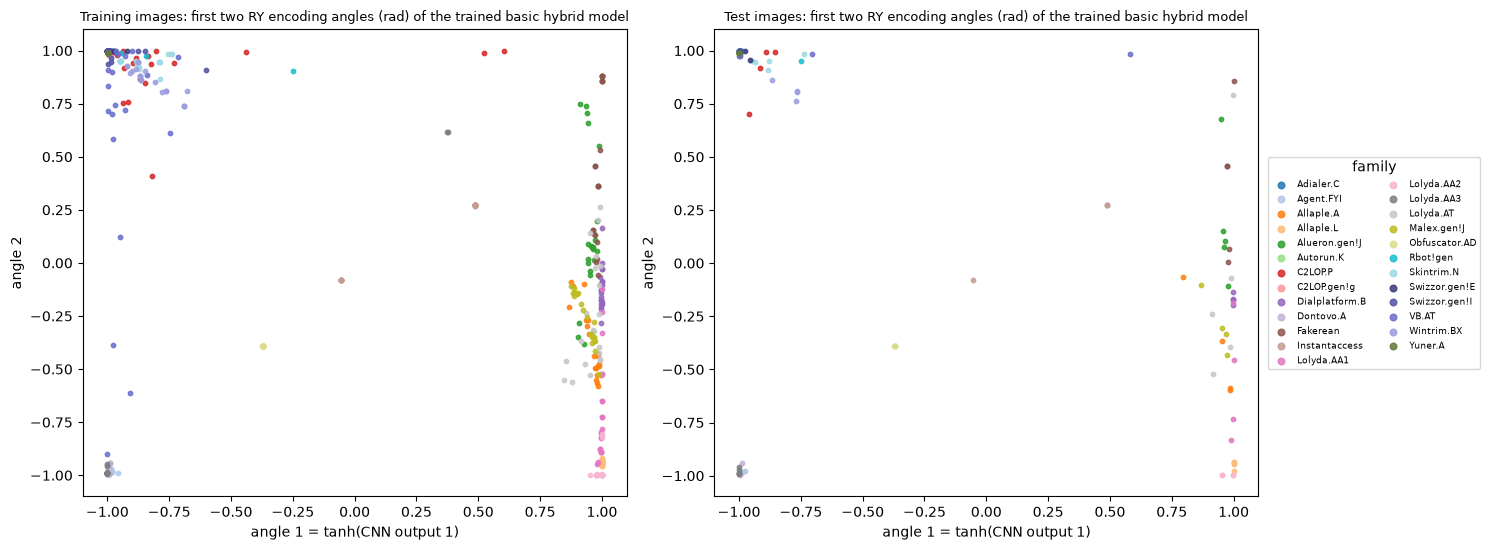

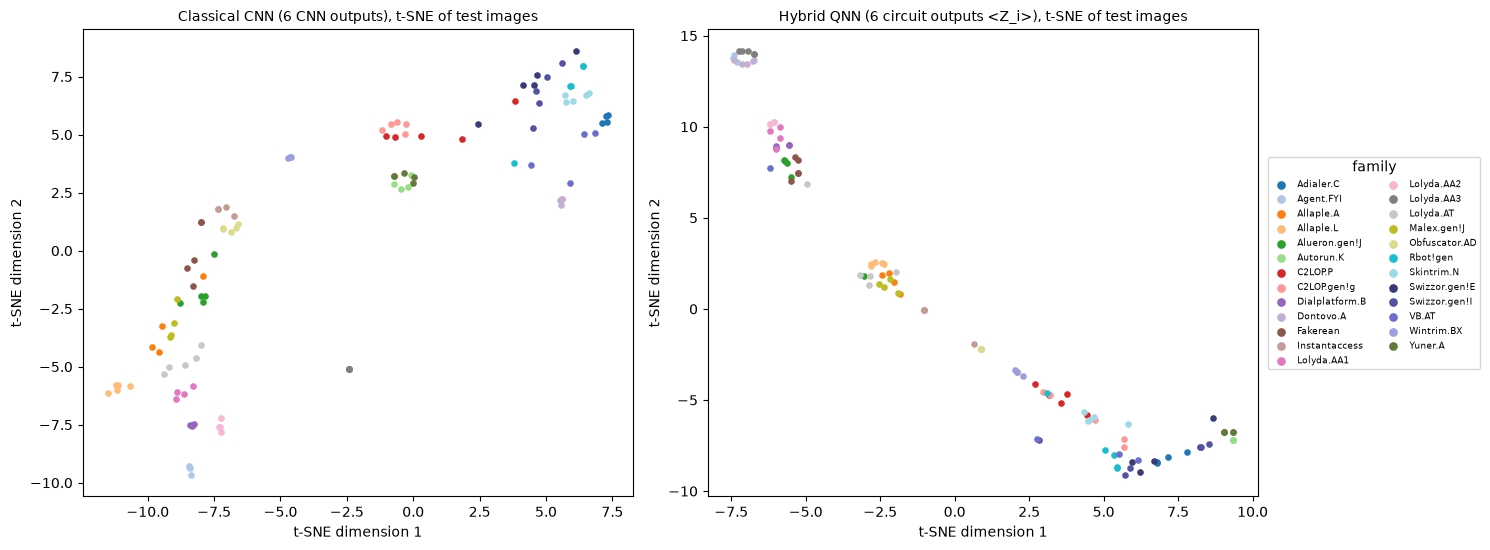

Table 6, this notebook (Malimg test images)


,CNN,QNI,H-QNN
Entropy,2.7907,2.5021,2.2029
Feature Variance,6.0781,0.1103,0.1479
Unique Patterns,19.0000,15.0000,14.0000
High-conf. patterns %,0.0000,0.0000,0.0000
Average confidence,0.3528,0.2583,0.2403
Confidence std. dev.,0.1344,0.1857,0.0955


Table 6, paper (Malimg)


,CNN,QNI,H-QNN
Entropy,2.5300,2.5215,2.5452
Feature Variance,7.7084,0.0996,0.1274
Unique Patterns,24.0000,24.0000,24.0000
High-conf. patterns %,78.1000,99.4000,73.7000
Average confidence,0.9360,0.9960,0.9100
Confidence std. dev.,0.1070,0.0270,0.1280


Table 4 style: PCA variance ratio (%) of the six latent angles, Malimg (paper: clean 50.2 / 37 / 6.5 / 3.7 / 2.2 / 0.0; adversarial 40.6 / 20.9 / 15.85 / 10 / 6.8 / 5.6)


,PC1,PC2,PC3,PC4,PC5,PC6
clean,57.700001,28.200001,9.9,2.3,1.7,0.3
FGSM eps=0.3,44.900002,27.000000,20.6,4.3,1.8,1.2


In [16]:
@torch.no_grad()
def rep_and_probs(name, X, batch=128):
    m = MODELS[name]; m.backend = "pennylane" if m.quantum else "fast"
    raw, lat, rep, pr = [], [], [], []
    with eval_mode(m):
        for i in range(0, len(X), batch):
            r = m.feature_extractor(prep(X[i:i + batch])); z = torch.tanh(r); q = m.q_layer(z)
            raw.append(r); lat.append(z); rep.append(q if m.quantum else r); pr.append(m.classifier(q).softmax(-1))
    m.backend = "fast"
    return torch.cat(raw), torch.cat(lat), torch.cat(rep), torch.cat(pr)

# (a) the real angles that enter the circuit, first two of six, from the basic hybrid model
_, lat_tr, _, _ = rep_and_probs("H0 hybrid basic", Xtr)
_, lat_te, _, _ = rep_and_probs("H0 hybrid basic", Xte)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, (L, yy, title) in zip(axes, [(lat_tr, ytr, "Training images"), (lat_te, yte, "Test images")]):
    for c in range(NUM_CLASSES):
        m_ = yy.numpy() == c; ax.scatter(L[m_, 0], L[m_, 1], s=10, color=FAM_COLORS[c], label=FAMILIES[c], alpha=0.85)
    ax.set_title(f"{title}: first two RY encoding angles (rad) of the trained basic hybrid model", fontsize=9)
    ax.set_xlabel("angle 1 = tanh(CNN output 1)"); ax.set_ylabel("angle 2")
axes[1].legend(ncol=2, fontsize=6.5, markerscale=1.5, loc="center left", bbox_to_anchor=(1.01, 0.5), title="family"); plt.tight_layout(); plt.show()

# (b) Fig. 4 style t-SNE of the representation before the head (test images)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, (name, title) in zip(axes, [("C0 classical basic", "Classical CNN (6 CNN outputs)"), ("H0 hybrid basic", "Hybrid QNN (6 circuit outputs <Z_i>)")]):
    _, _, rep, _ = rep_and_probs(name, Xte)
    emb = TSNE(n_components=2, perplexity=max(5, min(30, len(rep) // 5)), random_state=SEED, init="pca").fit_transform(rep.numpy())
    for c in range(NUM_CLASSES):
        m_ = yte.numpy() == c; ax.scatter(emb[m_, 0], emb[m_, 1], s=14, color=FAM_COLORS[c], label=FAMILIES[c])
    ax.set_title(title + ", t-SNE of test images", fontsize=10); ax.set_xlabel("t-SNE dimension 1"); ax.set_ylabel("t-SNE dimension 2")
axes[1].legend(ncol=2, fontsize=6.5, markerscale=1.4, loc="center left", bbox_to_anchor=(1.01, 0.5), title="family"); plt.tight_layout(); plt.show()

# (c) Table 6 statistics
def stats6(name):
    raw, lat, rep, pr = rep_and_probs(name, Xte)
    pred = pr.argmax(1).numpy(); conf = pr.max(1).values.numpy()
    p = np.bincount(pred, minlength=NUM_CLASSES) / len(pred); p = p[p > 0]
    return {"Entropy": float(-(p * np.log(p)).sum()), "Feature Variance": float(rep.var(0).mean()), "Unique Patterns": int(len(np.unique(pred))),
            "High-conf. patterns %": 100 * float((conf >= 0.9).mean()), "Average confidence": float(conf.mean()), "Confidence std. dev.": float(conf.std())}
T6 = pd.DataFrame({"CNN": stats6("C0 classical basic"), "QNI": stats6("H1 hybrid QNI-CCP"), "H-QNN": stats6("H0 hybrid basic")})
T6_PAPER = pd.DataFrame({"CNN": [2.5300, 7.7084, 24, 78.1, 0.936, 0.107], "QNI": [2.5215, 0.0996, 24, 99.4, 0.996, 0.027], "H-QNN": [2.5452, 0.1274, 24, 73.7, 0.910, 0.128]}, index=T6.index)
print("Table 6, this notebook (Malimg test images)"); display(T6.round(4))
print("Table 6, paper (Malimg)"); display(T6_PAPER)

# (d) Table 4: PCA variance ratio of the 6 latent angles, clean and under FGSM eps = 0.3 (basic hybrid model, test images)
m0 = MODELS["H0 hybrid basic"]; m0.backend = "fast"
Xadv = torch.cat([fgsm_attack(m0, prep(Xte[i:i + 128]), yte[i:i + 128], eps=0.3) for i in range(0, len(Xte), 128)])
with torch.no_grad(), eval_mode(m0): lat_adv = torch.cat([m0.latent(Xadv[i:i + 128]) for i in range(0, len(Xadv), 128)])
T4 = pd.DataFrame({"clean": 100 * PCA(6, random_state=SEED).fit(lat_te.numpy()).explained_variance_ratio_,
                   "FGSM eps=0.3": 100 * PCA(6, random_state=SEED).fit(lat_adv.numpy()).explained_variance_ratio_}, index=[f"PC{i}" for i in range(1, 7)]).T
print("Table 4 style: PCA variance ratio (%) of the six latent angles, Malimg (paper: clean 50.2 / 37 / 6.5 / 3.7 / 2.2 / 0.0; adversarial 40.6 / 20.9 / 15.85 / 10 / 6.8 / 5.6)")
display(T4.round(1))
del Xadv, lat_adv

## 7. The price of the quantum layer: throughput

The paper reports 54.8 images/s for the adversarially trained hybrid model against 7,621 images/s for the classical one. We time inference (forward pass only, batch 16, evaluation mode) for the classical model, the hybrid model through the PennyLane circuit, and the hybrid model through the fast PyTorch twin. Absolute numbers depend on the machine (shared CPU here); the ratio is the informative part.

In [17]:
def ips(name, backend, reps, per_sample=False):
    m = MODELS[name]; m.backend = backend; xb = prep(Xte[:BATCH]) if len(Xte) >= BATCH else prep(Xte)
    with torch.no_grad(), eval_mode(m):
        def fwd():
            if per_sample:                        # the authors' implementation: one circuit call per image, torch.stack([q_layer(f) for f in x])
                z = m.latent(xb)
                return m.classifier(torch.stack([m.q_layer(f[None])[0] for f in z]))
            return m(xb)
        fwd(); t0 = time.time()
        for _ in range(reps): fwd()
    m.backend = "fast"
    return reps * len(xb) / (time.time() - t0)
THR = {"classical (C2)": ips("C2 classical adv (M1)", "fast", 20),
       "hybrid, PennyLane circuit, batched (H2)": ips("H2 hybrid QSLP (M1)", "pennylane", 5),
       "hybrid, PennyLane circuit, one call per image (authors' style) (H2)": ips("H2 hybrid QSLP (M1)", "pennylane", 1, per_sample=True),
       "hybrid, PyTorch twin (H2)": ips("H2 hybrid QSLP (M1)", "fast", 20)}
display(pd.DataFrame({"images / second": THR}).round(1))
RATIO = THR["classical (C2)"] / THR["hybrid, PennyLane circuit, one call per image (authors' style) (H2)"]
print(f"classical / hybrid throughput ratio, authors' per-image style = {RATIO:.0f}x   (paper: 7,621 / 54.8 = {7621 / 54.8:.0f}x)")
print(f"classical / hybrid throughput ratio with batched circuit evaluation = {THR['classical (C2)'] / THR['hybrid, PennyLane circuit, batched (H2)']:.1f}x")

,images / second
classical (C2),529.8
"hybrid, PennyLane circuit, batched (H2)",48.2
"hybrid, PennyLane circuit, one call per image (authors' style) (H2)",18.3
"hybrid, PyTorch twin (H2)",477.9


classical / hybrid throughput ratio, authors' per-image style = 29x   (paper: 7,621 / 54.8 = 139x)
classical / hybrid throughput ratio with batched circuit evaluation = 11.0x


## 8. Ablation in the spirit of Table 2: circuit depth and CNOT pattern

Table 2 of the paper reports, for the basic model on Malimg, that more variational layers help (2 layers: 80 %, 3: 90 %, 6: 95 %) and that a **ring** CNOT pattern (an extra CNOT from the last qubit back to the first) hurts (95 % -> 81 %). Those rows also change the loss and training schedule, so they are not a clean ablation. Here the *only* thing that changes is the circuit (2 or 6 layers, linear or ring), with an identical short training budget (`ABLATION_EPOCHS`, focal loss). The ring variant uses the same exact simulator (its equivalence with PennyLane was asserted above).

In [18]:
ABL = {}
if RUN_ABLATION:
    for label, (L, ring) in {"2 layers, linear": (2, False), "6 layers, linear": (6, False), "6 layers, ring": (6, True)}.items():
        torch.manual_seed(SEED); m = HybridQNN(True, q_layers=L, ring=ring)
        h = train_model(m, "basic", ABLATION_EPOCHS, tag=f"ablation {label}")
        ABL[label] = dict(val_acc=h.val_acc.max(), test_acc=accuracy(m, Xte, yte))
    display(pd.DataFrame(ABL).T.round(3))
else:
    print("RUN_ABLATION = False: skipped")

[ablation 2 layers, linear] epoch  1/6  loss 3.0438  train acc 0.047  val acc 0.036  (6s)


[ablation 2 layers, linear] epoch  2/6  loss 3.0284  train acc 0.033  val acc 0.036  (8s)


[ablation 2 layers, linear] epoch  3/6  loss 2.9470  train acc 0.072  val acc 0.071  (9s)


[ablation 2 layers, linear] epoch  4/6  loss 2.6546  train acc 0.074  val acc 0.080  (8s)


[ablation 2 layers, linear] epoch  5/6  loss 2.4572  train acc 0.092  val acc 0.080  (7s)


...

[ablation 6 layers, ring] epoch  3/6  loss 2.7323  train acc 0.072  val acc 0.080  (8s)


[ablation 6 layers, ring] epoch  4/6  loss 2.5295  train acc 0.082  val acc 0.080  (8s)


[ablation 6 layers, ring] epoch  5/6  loss 2.4363  train acc 0.066  val acc 0.080  (7s)


[ablation 6 layers, ring] epoch  6/6  loss 2.3775  train acc 0.064  val acc 0.071  (5s)


,val_acc,test_acc
"2 layers, linear",0.107,0.133
"6 layers, linear",0.143,0.142
"6 layers, ring",0.080,0.080


## 9. Side-by-side comparison with the paper

Rule for the verdicts: a number is **reproduced** if it lies within 2 accuracy points (or 0.02 in F1) of the paper's value; otherwise **not reached** (lower) or **exceeded** (higher) with the gap. Qualitative claims are checked with the stated criterion. Claims that need MaleVis or a quantity the paper does not define are **cannot be checked**. The standard error of a single accuracy on this test set is printed above and should be kept in mind.

In [19]:
rows = []
def num(claim, paper, ours, tol=2.0, unit="%"):
    gap = ours - paper
    v = "reproduced" if abs(gap) <= tol else (f"not reached ({gap:+.1f} pts)" if gap < 0 else f"exceeded ({gap:+.1f} pts)")
    rows.append((claim, f"{paper:g}{unit}", f"{ours:.1f}{unit}", v))
def qual(claim, paper, ours, ok):
    rows.append((claim, paper, ours, "reproduced" if ok else "not reached"))
def cannot(claim, paper, why): rows.append((claim, paper, why, "cannot be checked"))

E = EVAL; pc = lambda n, k: 100 * E[n][k]
# Table 5 (validation accuracy; the paper's "v" column)
num("Table 5: basic hybrid QNN, validation accuracy", 94, 100 * VAL["H0 hybrid basic"])
num("Table 5: after QNI-CCP, validation accuracy", 97, 100 * VAL["H1 hybrid QNI-CCP"])
num("Table 5: after adversarial training (QSLP), validation accuracy", 95, 100 * VAL["H2 hybrid QSLP (M1)"])
# Table 7
for nm, label, p in [("H2 hybrid QSLP (M1)", "QSLP (M1)", (95.11, 90.32, 80.0)), ("C2 classical adv (M1)", "classical, adv-trained M1", (97.09, 95.84, 85.22)),
                     ("H3 hybrid basic+adv (M2)", "hybrid M2", (97.09, 95.11, 92.30)), ("C3 classical basic+adv (M2)", "classical M2", (97.61, 95.42, 93.24))]:
    for k, kk, pv in zip(["clean", "FGSM", "PGD"], ["acc_clean", "acc_fgsm", "acc_pgd"], p):
        num(f"Table 7: {label}, {k} accuracy", pv, pc(nm, kk))
# Section 4.5 qualitative claims
qual("Sec. 4.5: undefended hybrid collapses under PGD (< 10 % accuracy)", "< 10 %", f"{pc('H0 hybrid basic', 'acc_pgd'):.1f}%", pc("H0 hybrid basic", "acc_pgd") < 10)
qual("Sec. 4.5: undefended classical CNN collapses under PGD (< 10 % accuracy)", "< 10 %", f"{pc('C0 classical basic', 'acc_pgd'):.1f}%", pc("C0 classical basic", "acc_pgd") < 10)
qual("Sec. 4.5: QNI-CCP alone is not sufficient against PGD (QNI-CCP PGD acc well below QSLP's)", "QNI-CCP << QSLP",
     f"{pc('H1 hybrid QNI-CCP', 'acc_pgd'):.1f}% vs {pc('H2 hybrid QSLP (M1)', 'acc_pgd'):.1f}%", pc("H2 hybrid QSLP (M1)", "acc_pgd") - pc("H1 hybrid QNI-CCP", "acc_pgd") > 10)
qual("Sec. 4.5: adversarial training improves FGSM accuracy over the basic hybrid", "improves", f"{pc('H0 hybrid basic', 'acc_fgsm'):.1f}% -> {pc('H2 hybrid QSLP (M1)', 'acc_fgsm'):.1f}%", pc("H2 hybrid QSLP (M1)", "acc_fgsm") > pc("H0 hybrid basic", "acc_fgsm") + 2)
qual("Sec. 4.5: adversarial training improves PGD accuracy over the basic hybrid", "improves", f"{pc('H0 hybrid basic', 'acc_pgd'):.1f}% -> {pc('H2 hybrid QSLP (M1)', 'acc_pgd'):.1f}%", pc("H2 hybrid QSLP (M1)", "acc_pgd") > pc("H0 hybrid basic", "acc_pgd") + 2)
# RQ1
qual("RQ1: hybrid and classical reach similar clean accuracy (|diff| < 2 pts, 'no advantage' in accuracy)", "similar", f"{pc('H0 hybrid basic', 'acc_clean'):.1f}% vs {pc('C0 classical basic', 'acc_clean'):.1f}%",
     abs(pc("H0 hybrid basic", "acc_clean") - pc("C0 classical basic", "acc_clean")) < 2)
qual("Table 6: hybrid latent feature variance is much lower than the classical CNN's", "0.127 vs 7.71", f"{T6.loc['Feature Variance', 'H-QNN']:.3f} vs {T6.loc['Feature Variance', 'CNN']:.3f}", T6.loc["Feature Variance", "H-QNN"] < 0.5 * T6.loc["Feature Variance", "CNN"])
qual("Table 6: QNI-CCP model has the highest average confidence", "0.996 (QNI) > 0.936 > 0.910", f"{T6.loc['Average confidence', 'QNI']:.3f} / {T6.loc['Average confidence', 'CNN']:.3f} / {T6.loc['Average confidence', 'H-QNN']:.3f}",
     T6.loc["Average confidence", "QNI"] == T6.loc["Average confidence"].max())
qual("Throughput: hybrid (PennyLane, one circuit call per image) is much slower (> 20x) than classical", "139x slower", f"{RATIO:.0f}x slower", RATIO > 20)
# Table 2 ablation
if ABL and max(v["test_acc"] for v in ABL.values()) < 0.15:
    cannot("Table 2: deeper circuit beats shallower one; ring CNOT worse than linear", "95% / 80% / 81%", "all ablation runs stayed near chance level in the short budget, so the comparison is uninformative")
elif ABL:
    qual("Table 2: deeper circuit (6 layers) beats 2 layers", "95% > 80%", f"{100 * ABL['6 layers, linear']['test_acc']:.1f}% vs {100 * ABL['2 layers, linear']['test_acc']:.1f}%", ABL["6 layers, linear"]["test_acc"] > ABL["2 layers, linear"]["test_acc"])
    qual("Table 2: ring CNOT is worse than linear CNOT", "81% < 95%", f"{100 * ABL['6 layers, ring']['test_acc']:.1f}% vs {100 * ABL['6 layers, linear']['test_acc']:.1f}%", ABL["6 layers, ring"]["test_acc"] < ABL["6 layers, linear"]["test_acc"])
cannot("Table 5/7, Fig. 7: every MaleVis number (14,226 images, 10 qubits)", "e.g. 92 % train, 81 % val", "MaleVis is only available through a request form")
cannot("Fig. 4 claim 'clusters more compact and better separated' for the hybrid model", "visual", "inspect the t-SNE plots above; no numerical criterion in the paper")

CMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 120, "display.width", 250)
display(CMP.style.set_properties(**{"text-align": "left"}).hide(axis="index"))
print(CMP.verdict.str.extract(r"^(reproduced|not reached|exceeded|cannot be checked)")[0].value_counts().to_string())

claim,paper,this notebook,verdict
"Table 5: basic hybrid QNN, validation accuracy",94%,36.6%,not reached (-57.4 pts)
"Table 5: after QNI-CCP, validation accuracy",97%,37.5%,not reached (-59.5 pts)
"Table 5: after adversarial training (QSLP), validation accuracy",95%,8.0%,not reached (-87.0 pts)
"Table 7: QSLP (M1), clean accuracy",95.11%,8.0%,not reached (-87.1 pts)
"Table 7: QSLP (M1), FGSM accuracy",90.32%,8.0%,not reached (-82.4 pts)
"Table 7: QSLP (M1), PGD accuracy",80%,8.0%,not reached (-72.0 pts)
"Table 7: classical, adv-trained M1, clean accuracy",97.09%,22.1%,not reached (-75.0 pts)
"Table 7: classical, adv-trained M1, FGSM accuracy",95.84%,20.4%,not reached (-75.5 pts)
"Table 7: classical, adv-trained M1, PGD accuracy",85.22%,14.2%,not reached (-71.1 pts)
"Table 7: hybrid M2, clean accuracy",97.09%,40.7%,not reached (-56.4 pts)


0
not reached          20
reproduced            4
cannot be checked     3


## 10. Reading the paper critically

- **Budget caveat for the numbers above.** `FAST_MODE` trains on 525 images for 30 epochs (about 960 optimiser steps), i.e. roughly 5 % of the authors' 50 epochs over about 6,500 images (about 20,000 steps). On a laptop CPU one epoch of the full training set costs about 3 minutes for the basic stage and about 9 minutes for the adversarial stage, so the paper's budgets would need many hours. The models here are therefore badly under-trained (the hybrid reaches a few tens of percent accuracy, and the adversarially trained ones barely leave chance level), and most verdicts above are "not reached" because of training budget, not necessarily because the paper is wrong. What the FAST run does confirm is the *mechanics*: the circuit twin matches PennyLane, undefended models collapse under PGD, and the hybrid's latent feature variance is far below the classical one.
- **Datasets.** Only Malimg could be rerun; MaleVis (the harder dataset, where the paper's own numbers are 79-86 % validation accuracy) is behind a request form. Conclusions about "both datasets" are therefore untested here.
- **Quantum advantage (RQ1).** The paper itself says that the CNN and the hybrid model give "very similar results". The evidence for an advantage is a t-SNE picture and a lower latent feature variance. The latter is almost mechanical: quantum expectation values are bounded in [-1, 1], while the classical network's six outputs are unbounded, so a variance of 0.13 versus 7.7 compares different quantities rather than "better structure". A fair control would put a bounded layer (for example `tanh` or a random fixed rotation) in the classical model.
- **No quantum noise, no shots.** All experiments are exact, noiseless simulations (the limitations section admits it). The claim of robustness "in the NISQ era" is not tested; shot noise is the first thing to add (exercise 3).
- **QNI-CCP.** `eps_q` is about 0.027, so the latent perturbation is tiny, and it is built from `N_CNOT` and depth only, not from anything measured on the circuit. The paper itself finds it gives no accuracy gain and no pixel-space robustness (Table 5, Sec. 4.5); the useful ingredient of QSLP is the ordinary FGSM / PGD adversarial training. An ablation "adversarial training without QNI-CCP" is missing from the paper (exercise 2).
- **Attacks.** Only FGSM / PGD in the pixel space of the downsized 128 x 128 input, white box, on the whole network. There is no adaptive attack on the centroid computation, no black-box attack, and no check for gradient masking, although the hybrid model's gradient passes through a bounded, oscillating layer (Sec. 5 of the paper lists these as limitations).
- **Evaluation protocol.** The best checkpoint is chosen on the validation split, and the paper's Table 7 does not say whether the numbers are validation or test; the training-accuracy figures of Table 5 are not a generalisation measure. Class imbalance (3,000 versus 80 images) makes plain accuracy dominated by the *Allaple* families, so macro-F1 matters; the paper's class-wise heat-maps show several families at F1 = 0 for the undefended models.
- **Reproducibility.** Single run per model, no confidence intervals in the paper; test sets of ~1,400 images give an accuracy standard error of about 0.6 points, and the differences between rows of Table 7 are of that size.
- **Dataset size mismatch.** The mirror used here has 9,347 images (the paper counts 9,339), probably because of a few re-added duplicates; this does not change the picture.

## 11. Exercises

1. **Full run.** Set `FAST_MODE = False` and the epoch budgets to the paper's 50 (see the configuration cell). How do the clean, FGSM and PGD accuracies of QSLP move? Is the classical model still better under PGD?
2. **Ablate QNI-CCP.** Train the adversarial recipe *without* the QNI-CCP and centroid terms (loss `0.5 clean + 0.25 FGSM + 0.25 PGD`). Does QSLP's robustness depend on QNI-CCP at all?
3. **Shot noise.** Replace `default.qubit` by a device with `shots=1000` (or add depolarising noise with `qml.DepolarizingChannel`) and re-evaluate the trained QSLP model under FGSM / PGD. Does noise help (as claimed in the literature) or hurt?
4. **Stronger attack.** Evaluate with 50 PGD iterations and several random restarts, and with an eps sweep (0.01 ... 0.3). Plot accuracy against eps for the hybrid and the classical model. Is there any sign of gradient masking?
5. **Fair control for the latent variance.** Add a fixed bounded non-linearity (for example `sin`) in place of the quantum layer in the classical model and recompute Table 6. Does the "feature variance" advantage of the quantum layer survive?